<a href="https://colab.research.google.com/github/Shlok-11/Lstm-Stock-Price-Predictor/blob/main/FINAL_CODE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Post-COVID Stock Price Prediction | Stacked LSTM
**AAPL · Training: 2021–2022 · Validation: 2023 · Test: 2024**

One straightforward model, one fair baseline, minimal output.

### 01 · Install & import

In [1]:
%pip -q install yfinance tensorflow scikit-learn matplotlib pandas

In [2]:
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
os.environ["TF_DETERMINISTIC_OPS"] = "1"
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
LOOKBACK = 20

### 02 · Download AAPL closing prices

In [3]:
raw = yf.download("AAPL", start="2021-01-01", end="2025-01-01", auto_adjust=True, progress=False)
if raw.empty:
    raise RuntimeError("Yahoo Finance returned no data. Retry later or load a Date,Close CSV.")
if isinstance(raw.columns, pd.MultiIndex):
    raw.columns = raw.columns.get_level_values(0)
prices = raw[["Close"]].dropna().sort_index()
assert len(prices) > 500
print(f"Observations: {len(prices)} | {prices.index.min().date()} to {prices.index.max().date()}")

Observations: 1005 | 2021-01-04 to 2024-12-31


### 03 · Split chronologically & scale

In [4]:
train_mask = prices.index < "2023-01-01"
val_mask = (prices.index >= "2023-01-01") & (prices.index < "2024-01-01")
test_mask = (prices.index >= "2024-01-01") & (prices.index < "2025-01-01")
scaler = MinMaxScaler()
scaler.fit(prices.loc[train_mask, ["Close"]])  # No future data in fit
scaled = scaler.transform(prices[["Close"]]).ravel()
print("Train / validation / test days:", train_mask.sum(), val_mask.sum(), test_mask.sum())

Train / validation / test days: 503 250 252


### 04 · Create 20-day sequences

In [5]:
x, y, previous, dates = [], [], [], []
actual = prices["Close"].to_numpy()
for i in range(LOOKBACK, len(prices)):
    x.append(scaled[i-LOOKBACK:i])
    y.append(scaled[i])
    previous.append(actual[i-1])
    dates.append(prices.index[i])
x = np.asarray(x, dtype="float32").reshape(-1, LOOKBACK, 1)
y = np.asarray(y, dtype="float32")
previous = np.asarray(previous)
dates = pd.DatetimeIndex(dates)
train = dates < "2023-01-01"
val = (dates >= "2023-01-01") & (dates < "2024-01-01")
test = (dates >= "2024-01-01") & (dates < "2025-01-01")
print("LSTM input shape:", x[train].shape)

LSTM input shape: (483, 20, 1)


### 05 · Build the stacked LSTM

In [6]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(LOOKBACK, 1)),
    tf.keras.layers.LSTM(32, return_sequences=True),
    tf.keras.layers.LSTM(16),
    tf.keras.layers.Dense(1)
])
model.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss="mse")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 20, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,505 (29.32 KB)

 Trainable params: 7,505 (29.32 KB)

 Non-trainable params: 0 (0.00 B)

### 06 · Train the model

In [7]:
history = model.fit(
    x[train], y[train], validation_data=(x[val], y[val]),
    epochs=40, batch_size=32, shuffle=False, verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=7, restore_best_weights=True
    )]
)
print("Epochs completed:", len(history.history["loss"]))

Epochs completed: 40


### 07 · Training loss

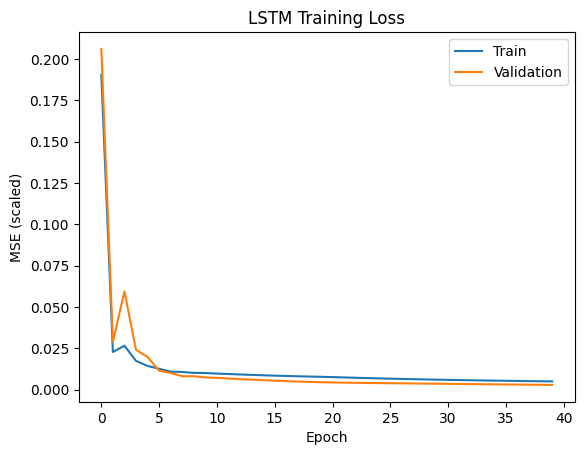

In [8]:
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("LSTM Training Loss"); plt.xlabel("Epoch"); plt.ylabel("MSE (scaled)")
plt.legend(); plt.show()

### 08 · Predict 2024 closing prices

In [9]:
y_pred = scaler.inverse_transform(model.predict(x[test], verbose=0)).ravel()
y_true = scaler.inverse_transform(y[test].reshape(-1, 1)).ravel()
y_naive = previous[test]  # Previous observed closing price
print("Test days:", len(y_true))

Test days: 252


### 09 · Compare LSTM with baseline
**Naive baseline:** predict today’s close using the previous trading day’s actual close.

In [10]:
def metrics(pred):
    return {
        "MSE": mean_squared_error(y_true, pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
        "MAE": mean_absolute_error(y_true, pred),
        "R²": r2_score(y_true, pred)
    }
results = pd.DataFrame({"LSTM": metrics(y_pred), "Previous-close": metrics(y_naive)}).T
print(results.round(3).to_string())

                  MSE   RMSE    MAE     R²
LSTM            43.95  6.629  5.434  0.932
Previous-close   8.32  2.885  2.122  0.987


### 10 · Plot actual vs predicted

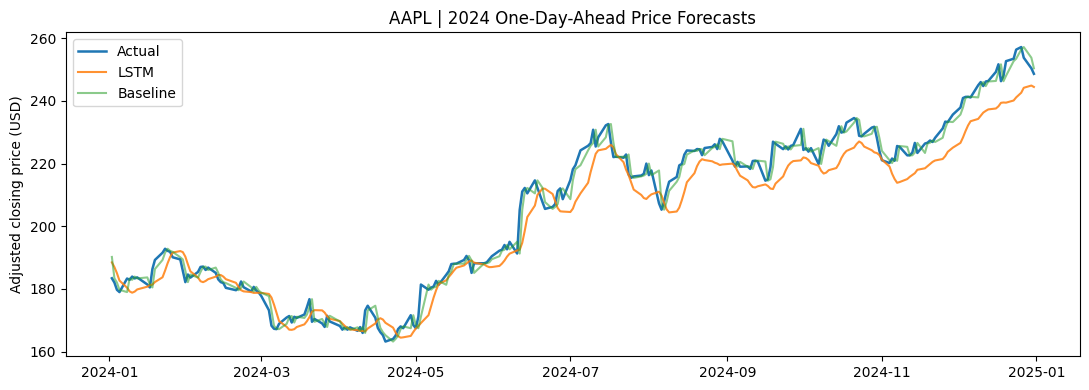

In [11]:
plt.figure(figsize=(11, 4))
plt.plot(dates[test], y_true, label="Actual", linewidth=1.8)
plt.plot(dates[test], y_pred, label="LSTM", alpha=0.85)
plt.plot(dates[test], y_naive, label="Baseline", alpha=0.55)
plt.title("AAPL | 2024 One-Day-Ahead Price Forecasts")
plt.ylabel("Adjusted closing price (USD)"); plt.legend(); plt.tight_layout(); plt.show()

### 11 · Export for Power BI

In [12]:
report = pd.DataFrame({
    "Date": dates[test], "Actual_Close": y_true,
    "LSTM_Prediction": y_pred, "Previous_Close_Baseline": y_naive
})
report.to_csv("aapl_post_covid_predictions_2024.csv", index=False)
results.to_csv("aapl_post_covid_model_metrics.csv")
print("Saved predictions and metrics CSV files")

Saved predictions and metrics CSV files


## Power BI Dashboard

The dashboard compares actual AAPL closing prices,
LSTM predictions, and the previous-close baseline
for the 2024 test period.

It also displays MSE, RMSE, MAE, and R².

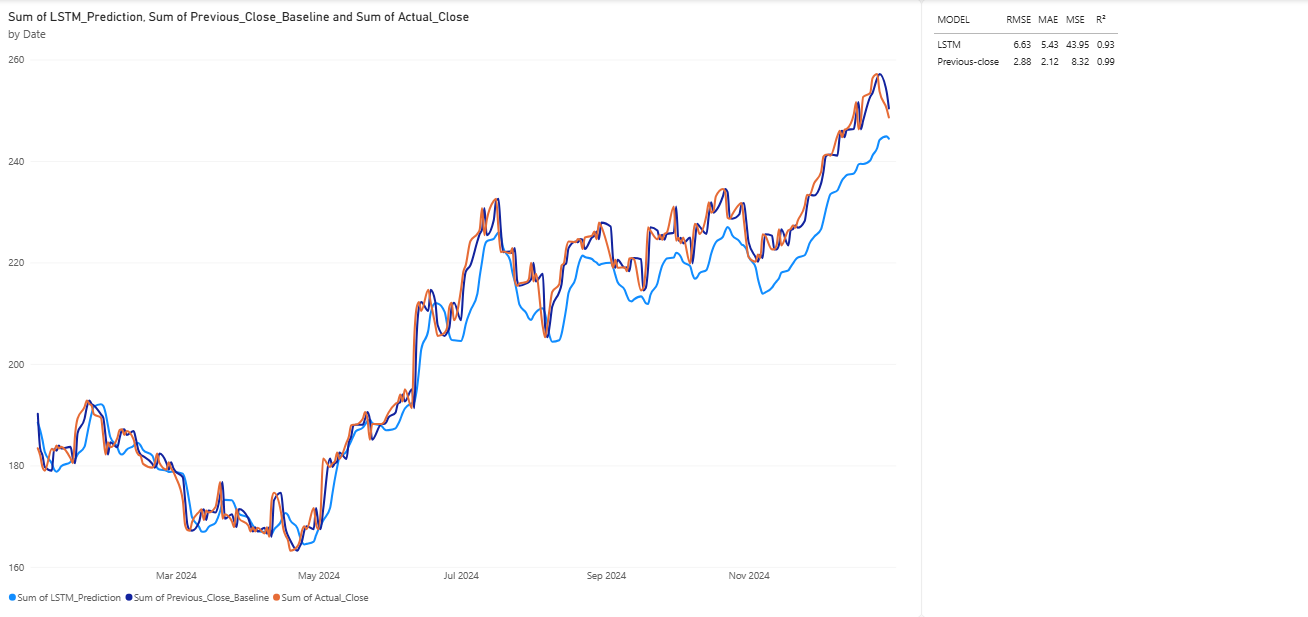

In [18]:
from IPython.display import Image, display

display(Image(filename="/content/Screenshot 2026-10-30 003159.png", width=900))